# DX602 Final Project: Exploratory Data Analysis & Linear Modeling of Bike-Sharing Demand

**Dataset Selected:** Option 3 — Outdoor Recreation (`bikes_final.csv`)

---

## Section 1: Introduction

Urban bike-sharing systems generate rich hourly operational records that connect human mobility patterns with weather and calendar rhythms. For this project, I selected **Option 3: Outdoor Recreation (`bikes_final.csv`)**, an hourly bike-sharing dataset containing **10,886 observations** across 2011 and 2012. *(Note: `bike_metadata.xlsx` was not included in the project directory, so variable definitions, seasonal quarter mappings, and data integrity constraints are verified directly from the dataset itself in Sections 2 and 3.)*

### Purpose of the Project
The purpose of this exploratory data analysis (EDA) and modeling project is to understand what drives hourly bike rental demand—both overall (`count`) and across rider segments (`casual` vs. `registered`)—and to test whether linear regression can explain rental volume from weather and calendar predictors.

### Key Questions to Investigate
1. **Calendar & Weather Drivers:** How do bike rentals vary by season, weather condition, day of the week, and working-day vs. weekend/holiday status?
2. **Temporal Trends & Co-movement:** How did bike-sharing demand evolve from 2011 to 2012, what does the hourly commuting profile look like, and how closely do monthly rentals track standardized temperature and humidity?
3. **Rider Composition:** When do casual riders represent a larger share of total trips compared to registered commuters?
4. **Predictive Modeling:** How strongly does temperature correlate with rental volume, and how well do simple and multiple linear regression models in `scikit-learn` predict hourly bike demand?

## Section 2: Load and Inspect the Data

In this section, we import the required Python libraries (`numpy`, `pandas`, `matplotlib`, and `sklearn`), configure consistent plotting defaults, load `bikes_final.csv`, and inspect its shape, column types, sample rows, unique value counts, and missing values.

In [1]:
# Core libraries for numerical computing, tabular analysis, plotting, and regression
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# Configure clean, consistent matplotlib styling across the notebook
plt.close("all")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

# Load the bike-sharing dataset
df_raw = pd.read_csv("bikes_final.csv")

print(f"Dataset shape: {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns")
df_raw.head()

Dataset shape: 10,886 rows x 13 columns


,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count,day_of_week
0,2011-01-01 00:00:00,1,0,0,1,9.84,14.395,81,0.0,3,13,16,Saturday
1,2011-01-01 01:00:00,1,0,0,1,9.02,13.635,80,0.0,8,32,40,Saturday
2,2011-01-01 02:00:00,1,0,0,1,9.02,13.635,80,0.0,5,27,32,Saturday
3,2011-01-01 03:00:00,1,0,0,1,9.84,14.395,75,0.0,3,10,13,Saturday
4,2011-01-01 04:00:00,1,0,0,1,9.84,14.395,75,0.0,0,1,1,Saturday


In [2]:
# Inspect the last few rows and structural metadata (column types, non-null counts)
display(df_raw.tail())
print("\n--- DataFrame Info ---")
df_raw.info()

,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count,day_of_week
10881,2012-12-19 19:00:00,4,0,1,1,15.58,19.695,50,26.0027,7,329,336,Wednesday
10882,2012-12-19 20:00:00,4,0,1,1,14.76,17.425,57,15.0013,10,231,241,Wednesday
10883,2012-12-19 21:00:00,4,0,1,1,13.94,15.910,61,15.0013,4,164,168,Wednesday
10884,2012-12-19 22:00:00,4,0,1,1,13.94,17.425,61,6.0032,12,117,129,Wednesday
10885,2012-12-19 23:00:00,4,0,1,1,13.12,16.665,66,8.9981,4,84,88,Wednesday



--- DataFrame Info ---
<class 'pandas.DataFrame'>
RangeIndex: 10886 entries, 0 to 10885
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   datetime     10886 non-null  str    
 1   season       10886 non-null  int64  
 2   holiday      10886 non-null  int64  
 3   workingday   10886 non-null  int64  
 4   weather      10886 non-null  int64  
 5   temp         10886 non-null  float64
 6   atemp        10886 non-null  float64
 7   humidity     10886 non-null  int64  
 8   windspeed    10886 non-null  float64
 9   casual       10886 non-null  int64  
 10  registered   10886 non-null  int64  
 11  count        10886 non-null  int64  
 12  day_of_week  10886 non-null  str    
dtypes: float64(3), int64(8), str(2)
memory usage: 1.1 MB


In [3]:
# Check missing values and unique counts per column using a summary DataFrame
inspection_df = pd.DataFrame({
    "dtype": df_raw.dtypes.astype(str),
    "missing_count": df_raw.isnull().sum(),
    "missing_pct": (df_raw.isnull().mean() * 100).round(2),
    "n_unique": df_raw.nunique(),
})
inspection_df

,dtype,missing_count,missing_pct,n_unique
datetime,str,0,0.0,10886
season,int64,0,0.0,4
holiday,int64,0,0.0,2
workingday,int64,0,0.0,2
weather,int64,0,0.0,4
temp,float64,0,0.0,49
atemp,float64,0,0.0,60
humidity,int64,0,0.0,89
windspeed,float64,0,0.0,28
casual,int64,0,0.0,309


### Initial Inspection Takeaways
* The dataset contains **10,886 rows and 13 columns** with **zero missing (`NaN`) values**.
* `datetime` is currently stored as a text/string column (`str`/`object`) and needs to be parsed into a proper `datetime64` column.
* `season` (4 unique values), `holiday` (2), `workingday` (2), `weather` (4), and `day_of_week` (7) represent categorical features, while `temp`, `atemp`, `humidity`, `windspeed`, `casual`, `registered`, and `count` are numerical.

## Section 3: Data Cleaning and Preparation

Even when a dataset has zero `NaN` values, careful preparation is essential before analysis. Here we:
1. Check for duplicate rows and verify that `count == casual + registered` holds for every record.
2. Parse `datetime`, sort chronologically, and verify the date coverage (`2011-01-01` through `2012-12-19`).
3. Inspect the meaning of numeric codes (`season` and `weather`) directly against calendar months and temperatures, and examine potential sensor anomalies such as `windspeed == 0.0` or rare weather categories.
4. Build a clean analysis DataFrame `df_bikes` with parsed calendar columns (`year`, `month`, `hour`, `year_month`, `date`) and human-readable categorical labels.

In [4]:
def inspect_data_quality(df):
    """Run structural integrity checks on the raw bike-sharing DataFrame."""
    # Check exact duplicate rows and duplicate timestamps
    dup_rows = df.duplicated().sum()
    dup_times = df["datetime"].duplicated().sum()

    # Verify accounting identity: total count should equal casual + registered
    count_matches = (df["count"] == df["casual"] + df["registered"]).all()

    # Count zero windspeed readings (commonly below anemometer threshold / unrecorded)
    zero_wind = (df["windspeed"] == 0).sum()

    # Check distribution of weather codes and rare extreme weather rows
    weather_counts = df["weather"].value_counts().sort_index()

    print(f"Exact duplicate rows: {dup_rows}")
    print(f"Duplicate timestamps: {dup_times}")
    print(f"Identity (count == casual + registered) holds everywhere: {count_matches}")
    print(f"Zero windspeed readings: {zero_wind:,} ({zero_wind / len(df) * 100:.2f}% of rows)")
    print("\nWeather code counts:")
    print(weather_counts)


inspect_data_quality(df_raw)

Exact duplicate rows: 0
Duplicate timestamps: 0
Identity (count == casual + registered) holds everywhere: True
Zero windspeed readings: 1,313 (12.06% of rows)

Weather code counts:
weather
1    7192
2    2834
3     859
4       1
Name: count, dtype: int64


In [5]:
# Create a cleaned working copy and convert datetime
df_bikes = df_raw.copy()
df_bikes["datetime"] = pd.to_datetime(df_bikes["datetime"])
df_bikes = df_bikes.sort_values("datetime").reset_index(drop=True)

# Extract useful time components
df_bikes["year"] = df_bikes["datetime"].dt.year
df_bikes["month"] = df_bikes["datetime"].dt.month
df_bikes["day"] = df_bikes["datetime"].dt.day
df_bikes["hour"] = df_bikes["datetime"].dt.hour
df_bikes["date"] = df_bikes["datetime"].dt.date
df_bikes["year_month"] = df_bikes["datetime"].dt.to_period("M").astype(str)

# Verify date range and how many days per month are included
days_per_month = df_bikes.groupby(["year", "month"])["day"].nunique()
print(f"Date range: {df_bikes['datetime'].min()} to {df_bikes['datetime'].max()}")
print(f"Days observed per month (min / max): {days_per_month.min()} / {days_per_month.max()}")

# Verify which calendar months and average temperatures belong to each season code
season_check = df_bikes.groupby("season").agg(
    months=("month", lambda s: sorted(s.unique().tolist())),
    avg_temp_c=("temp", "mean"),
    avg_count=("count", "mean"),
    rows=("count", "size"),
)
season_check

Date range: 2011-01-01 00:00:00 to 2012-12-19 23:00:00
Days observed per month (min / max): 19 / 19


,months,avg_temp_c,avg_count,rows
season,,,,
1,"[1, 2, 3]",12.530491,116.343261,2686
2,"[4, 5, 6]",22.823483,215.251372,2733
3,"[7, 8, 9]",28.789111,234.417124,2733
4,"[10, 11, 12]",16.649239,198.988296,2734


In [6]:
# Map numeric codes to descriptive labels verified from months/temperatures above:
# Code 1 covers Jan-Mar (coldest, avg 12.5 C), 2 covers Apr-Jun (22.8 C),
# 3 covers Jul-Sep (warmest, 28.8 C), and 4 covers Oct-Dec (16.6 C).
season_map = {
    1: "Q1: Winter (Jan-Mar)",
    2: "Q2: Spring (Apr-Jun)",
    3: "Q3: Summer (Jul-Sep)",
    4: "Q4: Fall (Oct-Dec)",
}
weather_map = {
    1: "Clear / Partly Cloudy",
    2: "Mist / Cloudy",
    3: "Light Snow / Rain",
    4: "Heavy Rain / Snow",
}

df_bikes["season_label"] = pd.Categorical(
    df_bikes["season"].map(season_map),
    categories=list(season_map.values()),
    ordered=True,
)
df_bikes["weather_label"] = pd.Categorical(
    df_bikes["weather"].map(weather_map),
    categories=list(weather_map.values()),
    ordered=True,
)

# Order day_of_week chronologically from Monday to Sunday
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
df_bikes["day_of_week"] = pd.Categorical(
    df_bikes["day_of_week"],
    categories=weekday_order,
    ordered=True,
)


# Create a single readable day_type category combining holiday and workingday
def classify_day_type(row):
    """Classify each observation into Working Day, Weekend, or Holiday."""
    if row["holiday"] == 1:
        return "Holiday"
    elif row["workingday"] == 1:
        return "Working Day"
    return "Weekend"


df_bikes["day_type"] = pd.Categorical(
    df_bikes.apply(classify_day_type, axis=1),
    categories=["Working Day", "Weekend", "Holiday"],
    ordered=True,
)

# Flag zero-windspeed observations and create a cleaned windspeed column for sensitivity checks
df_bikes["windspeed_is_zero"] = df_bikes["windspeed"] == 0
nonzero_wind_medians = (
    df_bikes[~df_bikes["windspeed_is_zero"]]
    .groupby("month")["windspeed"]
    .transform("median")
)
monthly_wind_medians = (
    df_bikes[~df_bikes["windspeed_is_zero"]]
    .groupby("month")["windspeed"]
    .median()
)
df_bikes["windspeed_clean"] = np.where(
    df_bikes["windspeed_is_zero"],
    df_bikes["month"].map(monthly_wind_medians),
    df_bikes["windspeed"],
)

print("Cleaned DataFrame preview:")
df_bikes[
    ["datetime", "season_label", "weather_label", "day_type", "day_of_week",
     "temp", "humidity", "windspeed", "windspeed_clean", "casual", "registered", "count"]
].head()

Cleaned DataFrame preview:


,datetime,season_label,weather_label,day_type,day_of_week,temp,humidity,windspeed,windspeed_clean,casual,registered,count
0,2011-01-01 00:00:00,Q1: Winter (Jan-Mar),Clear / Partly Cloudy,Weekend,Saturday,9.84,81,0.0,15.0013,3,13,16
1,2011-01-01 01:00:00,Q1: Winter (Jan-Mar),Clear / Partly Cloudy,Weekend,Saturday,9.02,80,0.0,15.0013,8,32,40
2,2011-01-01 02:00:00,Q1: Winter (Jan-Mar),Clear / Partly Cloudy,Weekend,Saturday,9.02,80,0.0,15.0013,5,27,32
3,2011-01-01 03:00:00,Q1: Winter (Jan-Mar),Clear / Partly Cloudy,Weekend,Saturday,9.84,75,0.0,15.0013,3,10,13
4,2011-01-01 04:00:00,Q1: Winter (Jan-Mar),Clear / Partly Cloudy,Weekend,Saturday,9.84,75,0.0,15.0013,0,1,1


### Data Cleaning Summary
* **No missing values or duplicates:** All 10,886 hourly records are unique, and `count == casual + registered` holds for 100% of rows.
* **Sampling window discovered:** Every month from January 2011 through December 2012 includes days **1 through 19** (19 days per month × 24 months ≈ 456 days), meaning end-of-month days (20–31) are not present in this dataset.
* **Season verification:** Checking months and temperatures revealed that `season = 1` corresponds to **Jan–Mar (12.5°C)**, `2` to **Apr–Jun (22.8°C)**, `3` to **Jul–Sep (28.8°C)**, and `4` to **Oct–Dec (16.6°C)**—matching Washington, D.C. meteorological quarters (Q1 Winter through Q4 Fall).
* **Windspeed & rare weather:** Exactly **1,313 rows (12.06%)** record `windspeed = 0.0`, likely representing calm winds below sensor reporting threshold; we added a `windspeed_is_zero` flag and `windspeed_clean` (monthly non-zero median) while preserving raw `windspeed` for transparency. Also, `weather = 4` (`Heavy Rain / Snow`) has only **1 observation** (`2012-01-09 18:00:00`).

## Section 4: Descriptive Statistics

We now compute comprehensive descriptive statistics for both numerical variables (center, spread, quartiles, IQR, and skewness) and categorical variables (counts and proportions) using reusable helper functions.

In [7]:
def summarize_numeric(df, columns):
    """Return extended descriptive statistics (including median, IQR, and skew) for numeric columns."""
    stats_rows = []
    # Loop over requested numerical columns to build a unified summary table
    for col in columns:
        series = df[col]
        q1 = series.quantile(0.25)
        q3 = series.quantile(0.75)
        stats_rows.append({
            "column": col,
            "count": int(series.count()),
            "mean": round(series.mean(), 2),
            "std": round(series.std(), 2),
            "min": round(series.min(), 2),
            "25% (Q1)": round(q1, 2),
            "median (50%)": round(series.median(), 2),
            "75% (Q3)": round(q3, 2),
            "IQR": round(q3 - q1, 2),
            "max": round(series.max(), 2),
            "skewness": round(series.skew(), 2),
        })
    return pd.DataFrame(stats_rows).set_index("column")


def summarize_categorical(df, columns):
    """Print frequency counts and percentage shares for a list of categorical columns."""
    for col in columns:
        counts = df[col].value_counts(dropna=False)
        pcts = (df[col].value_counts(normalize=True, dropna=False) * 100).round(2)
        summary = pd.DataFrame({"count": counts, "percent (%)": pcts})
        print(f"\n=== Category Summary: {col} ===")
        display(summary)


numeric_cols = ["temp", "atemp", "humidity", "windspeed", "casual", "registered", "count"]
categorical_cols = ["season_label", "weather_label", "day_type", "day_of_week", "year"]

numeric_summary = summarize_numeric(df_bikes, numeric_cols)
display(numeric_summary)
summarize_categorical(df_bikes, categorical_cols)

,count,mean,std,min,25% (Q1),median (50%),75% (Q3),IQR,max,skewness
column,,,,,,,,,,
temp,10886,20.23,7.79,0.82,13.94,20.50,26.24,12.3,41.00,0.00
atemp,10886,23.66,8.47,0.76,16.66,24.24,31.06,14.4,45.46,-0.10
humidity,10886,61.89,19.25,0.00,47.00,62.00,77.00,30.0,100.00,-0.09
windspeed,10886,12.80,8.16,0.00,7.00,13.00,17.00,10.0,57.00,0.59
casual,10886,36.02,49.96,0.00,4.00,17.00,49.00,45.0,367.00,2.50
registered,10886,155.55,151.04,0.00,36.00,118.00,222.00,186.0,886.00,1.52
count,10886,191.57,181.14,1.00,42.00,145.00,284.00,242.0,977.00,1.24



=== Category Summary: season_label ===


,count,percent (%)
season_label,,
Q4: Fall (Oct-Dec),2734,25.11
Q2: Spring (Apr-Jun),2733,25.11
Q3: Summer (Jul-Sep),2733,25.11
Q1: Winter (Jan-Mar),2686,24.67



=== Category Summary: weather_label ===


,count,percent (%)
weather_label,,
Clear / Partly Cloudy,7192,66.07
Mist / Cloudy,2834,26.03
Light Snow / Rain,859,7.89
Heavy Rain / Snow,1,0.01



=== Category Summary: day_type ===


,count,percent (%)
day_type,,
Working Day,7412,68.09
Weekend,3163,29.06
Holiday,311,2.86



=== Category Summary: day_of_week ===


,count,percent (%)
day_of_week,,
Saturday,1584,14.55
Sunday,1579,14.50
Thursday,1553,14.27
Monday,1551,14.25
Wednesday,1551,14.25
Tuesday,1539,14.14
Friday,1529,14.05



=== Category Summary: year ===


,count,percent (%)
year,,
2012,5464,50.19
2011,5422,49.81


### Descriptive Statistics Insights
* **Bike Rental Volume (`count`):** Mean hourly rentals are **191.57** (std = **181.14**), notably higher than the median of **145.00** (skewness = **1.24**). This strong right skew reflects quiet overnight hours (`min = 1`) contrasted with sharp daytime commuting peaks (`max = 977`).
* **User Segments:** Registered users account for the vast majority of demand (mean **155.55/hr**, ~81.2% of average rentals) compared to casual riders (mean **36.02/hr**, skewness **2.50**).
* **Weather Conditions:** Temperatures average **20.23°C** (ranging from 0.82°C to 41.00°C), humidity averages **61.89%**, and nearly **two-thirds (66.07%)** of all hours occur under Clear/Partly Cloudy skies.
* **Balanced Calendar Coverage:** All four seasons (~2,686–2,734 rows each), both years (5,422 in 2011 vs. 5,464 in 2012), and all seven days of the week (~1,539–1,584 rows each) are very evenly represented.

## Section 5: Numerical Data Visualizations

To understand the range, spread, skew, and outliers of the numerical variables, we create:
1. **Histograms** (with mean and median reference lines) for `count`, `temp`, `humidity`, and `windspeed`.
2. **Box plots** comparing weather variables and rider volume distributions.
3. **A bar chart** showing average hourly rentals across the 24 hours of the day.

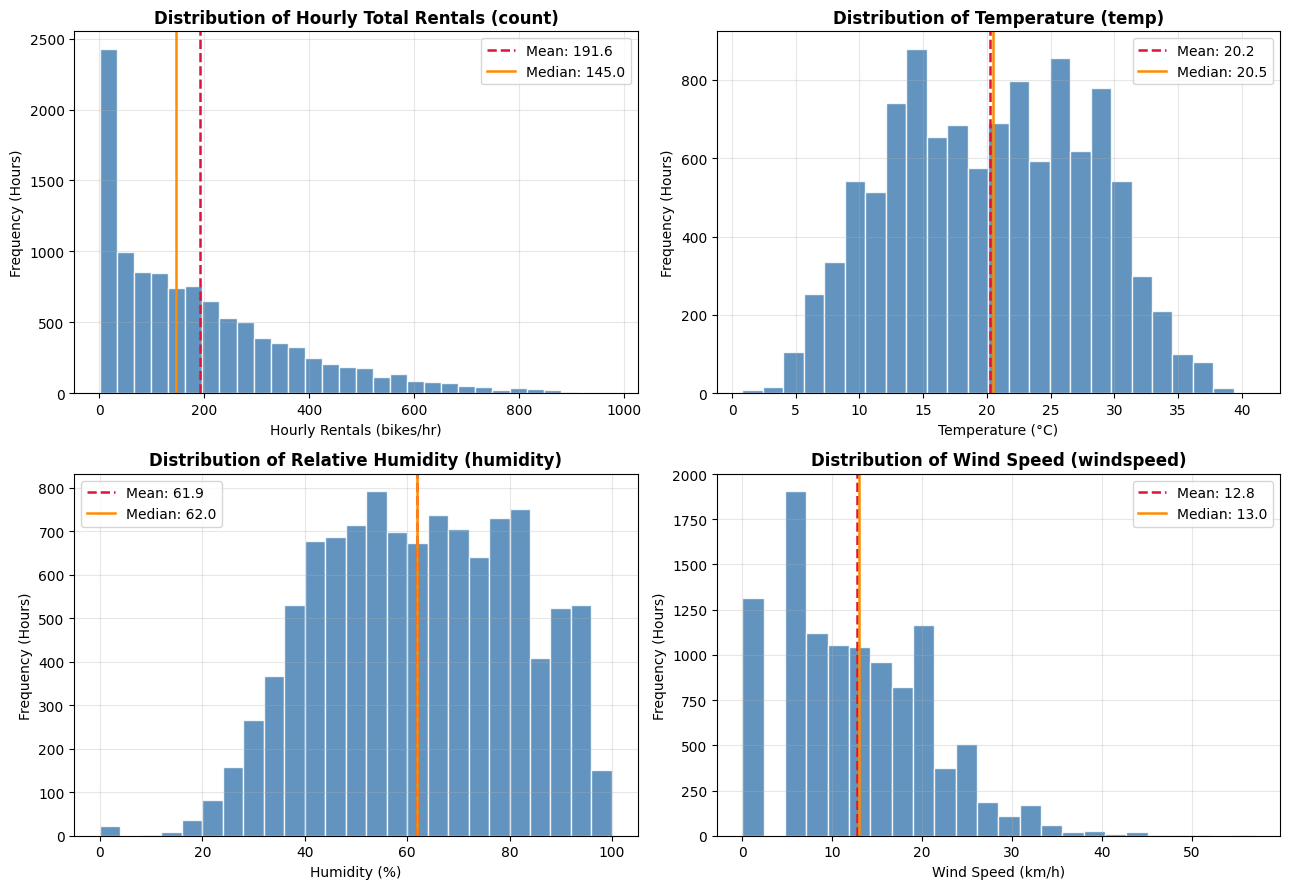

In [8]:
def plot_histogram_grid(df, columns, titles, xlabels, bins_list, ncols=2):
    """Plot a grid of histograms with vertical mean and median lines."""
    nrows = int(np.ceil(len(columns) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(13, 4.5 * nrows))
    axes = np.atleast_1d(axes).flatten()

    # Loop over columns and render each histogram in its subplot
    for i, col in enumerate(columns):
        ax = axes[i]
        data = df[col].dropna()
        ax.hist(data, bins=bins_list[i], color="steelblue", edgecolor="white", alpha=0.85)
        mean_val = data.mean()
        med_val = data.median()
        ax.axvline(mean_val, color="crimson", linestyle="--", linewidth=1.8, label=f"Mean: {mean_val:.1f}")
        ax.axvline(med_val, color="darkorange", linestyle="-", linewidth=1.8, label=f"Median: {med_val:.1f}")
        ax.set_title(titles[i], fontsize=12, fontweight="bold")
        ax.set_xlabel(xlabels[i])
        ax.set_ylabel("Frequency (Hours)")
        ax.legend()

    # Hide unused subplot panels if any
    for j in range(len(columns), len(axes)):
        axes[j].set_visible(False)

    plt.tight_layout()
    plt.show()


plot_histogram_grid(
    df_bikes,
    columns=["count", "temp", "humidity", "windspeed"],
    titles=[
        "Distribution of Hourly Total Rentals (count)",
        "Distribution of Temperature (temp)",
        "Distribution of Relative Humidity (humidity)",
        "Distribution of Wind Speed (windspeed)",
    ],
    xlabels=["Hourly Rentals (bikes/hr)", "Temperature (°C)", "Humidity (%)", "Wind Speed (km/h)"],
    bins_list=[30, 25, 25, 24],
)

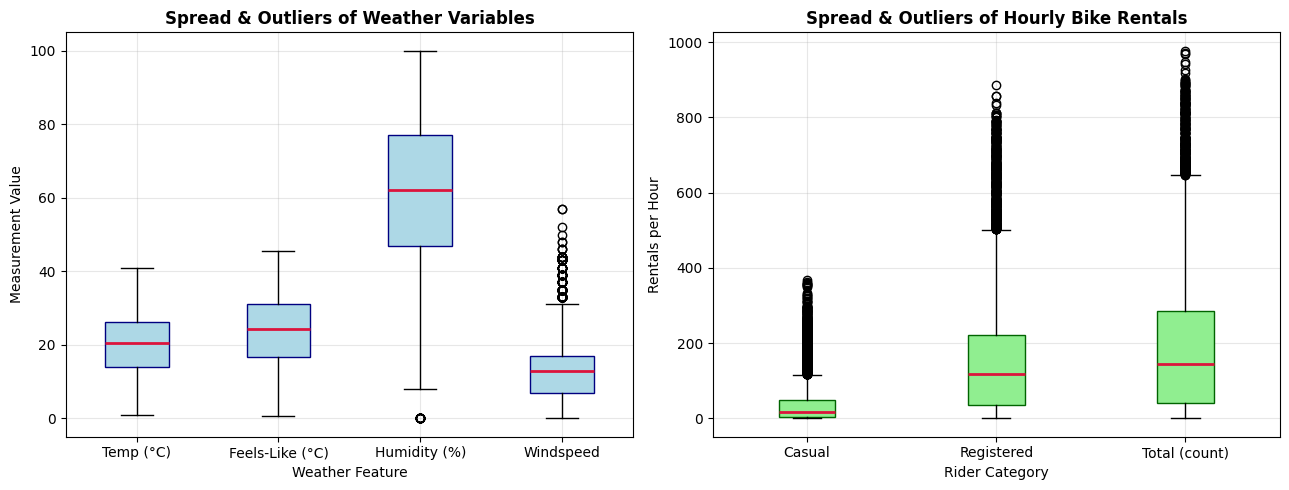

In [9]:
# Box plots: side-by-side comparison of weather metrics (left) and rental counts (right)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

weather_box_cols = ["temp", "atemp", "humidity", "windspeed"]
ax1.boxplot([df_bikes[c] for c in weather_box_cols], patch_artist=True,
            boxprops=dict(facecolor="lightblue", color="navy"),
            medianprops=dict(color="crimson", linewidth=2))
ax1.set_xticks(range(1, len(weather_box_cols) + 1))
ax1.set_xticklabels(["Temp (°C)", "Feels-Like (°C)", "Humidity (%)", "Windspeed"])
ax1.set_title("Spread & Outliers of Weather Variables", fontsize=12, fontweight="bold")
ax1.set_xlabel("Weather Feature")
ax1.set_ylabel("Measurement Value")

rental_box_cols = ["casual", "registered", "count"]
ax2.boxplot([df_bikes[c] for c in rental_box_cols], patch_artist=True,
            boxprops=dict(facecolor="lightgreen", color="darkgreen"),
            medianprops=dict(color="crimson", linewidth=2))
ax2.set_xticks(range(1, len(rental_box_cols) + 1))
ax2.set_xticklabels(["Casual", "Registered", "Total (count)"])
ax2.set_title("Spread & Outliers of Hourly Bike Rentals", fontsize=12, fontweight="bold")
ax2.set_xlabel("Rider Category")
ax2.set_ylabel("Rentals per Hour")

plt.tight_layout()
plt.show()

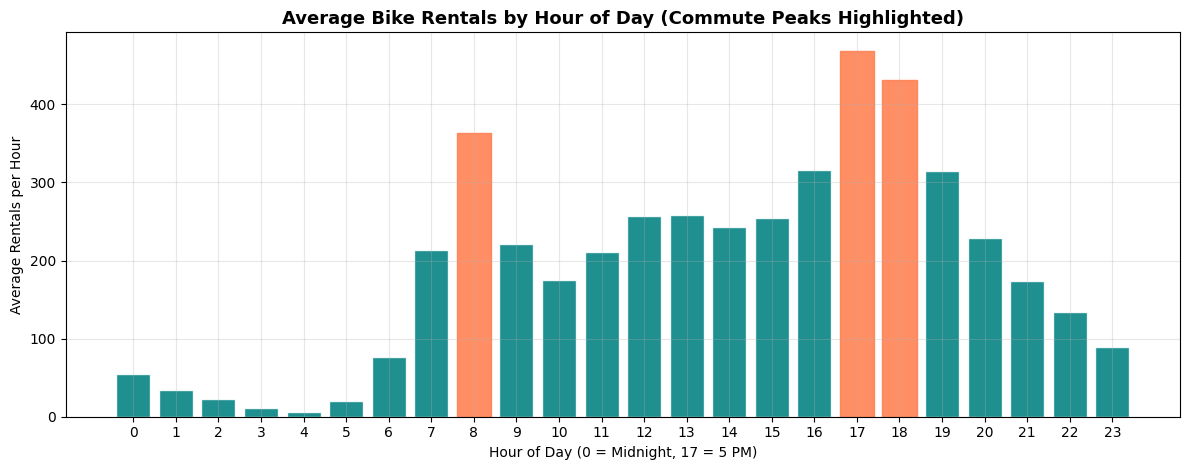

In [10]:
# Bar chart: Average hourly rentals across the 24 hours of the day
hourly_avg = df_bikes.groupby("hour")["count"].mean()

fig, ax = plt.subplots(figsize=(12, 4.8))
bars = ax.bar(hourly_avg.index, hourly_avg.values, color="teal", edgecolor="white", alpha=0.88)

# Highlight peak commute hours (8 AM and 5-6 PM) in coral
for idx, bar in enumerate(bars):
    if idx in [8, 17, 18]:
        bar.set_color("coral")

ax.set_title("Average Bike Rentals by Hour of Day (Commute Peaks Highlighted)", fontsize=13, fontweight="bold")
ax.set_xlabel("Hour of Day (0 = Midnight, 17 = 5 PM)")
ax.set_ylabel("Average Rentals per Hour")
ax.set_xticks(range(0, 24))
plt.tight_layout()
plt.show()

### What the Numerical Visualizations Reveal
* **`count` is strongly right-skewed:** Many overnight hours record fewer than 50 rentals, pulling the median (145) well below the mean (191.6), while upper-tail outliers reach up to 977 rentals/hour.
* **`temp` and `humidity`:** Temperature shows a broad, slightly bimodal warm/cool distribution (reflecting winter vs. summer months), whereas humidity is roughly bell-shaped around ~62%.
* **`windspeed` spike at 0:** The leftmost bar in the `windspeed` histogram highlights the 1,313 zero-windspeed records noted during cleaning.
* **Bimodal daily demand:** The hourly bar chart reveals sharp commuter spikes at **8 AM (~363/hr)** and **5–6 PM (~469 and ~431/hr)**, and very low overnight activity from midnight to 5 AM.

## Section 6: Categorical Data Analysis

Next, we visualize the distributions of the dataset's key categorical features (`season_label`, `day_of_week`, `weather_label`, and `day_type`), along with the overall share of `casual` vs. `registered` rentals, using bar charts and pie charts.

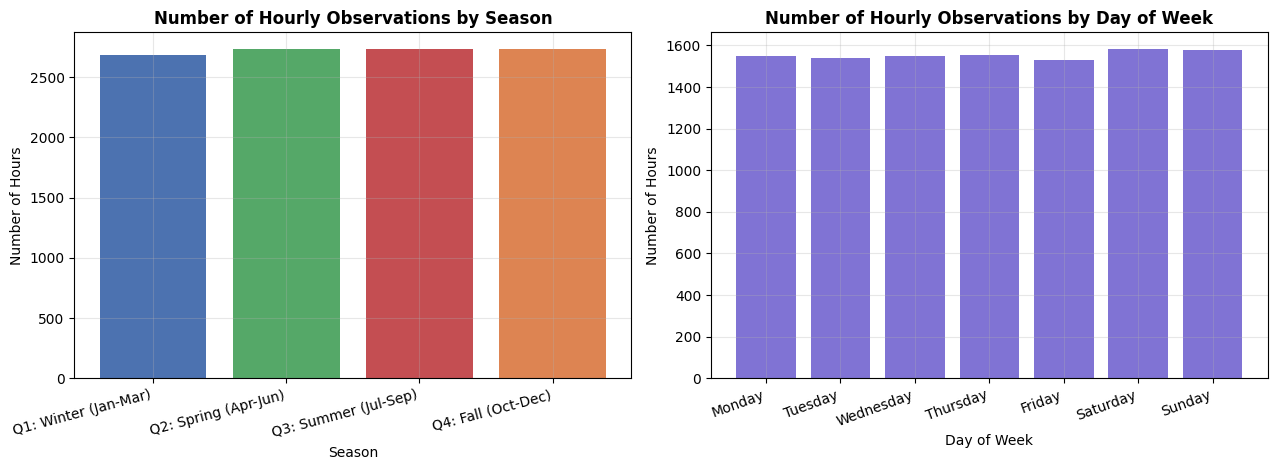

In [11]:
# Bar charts for Season and Day of Week record counts
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))

season_counts = df_bikes["season_label"].value_counts().reindex(df_bikes["season_label"].cat.categories)
ax1.bar(season_counts.index, season_counts.values, color=["#4C72B0", "#55A868", "#C44E52", "#DD8452"])
ax1.set_title("Number of Hourly Observations by Season", fontsize=12, fontweight="bold")
ax1.set_xlabel("Season")
ax1.set_ylabel("Number of Hours")
ax1.set_xticks(range(len(season_counts)))
ax1.set_xticklabels(season_counts.index, rotation=15, ha="right")

dow_counts = df_bikes["day_of_week"].value_counts().reindex(df_bikes["day_of_week"].cat.categories)
ax2.bar(dow_counts.index, dow_counts.values, color="slateblue", alpha=0.85)
ax2.set_title("Number of Hourly Observations by Day of Week", fontsize=12, fontweight="bold")
ax2.set_xlabel("Day of Week")
ax2.set_ylabel("Number of Hours")
ax2.set_xticks(range(len(dow_counts)))
ax2.set_xticklabels(dow_counts.index, rotation=20, ha="right")

plt.tight_layout()
plt.show()

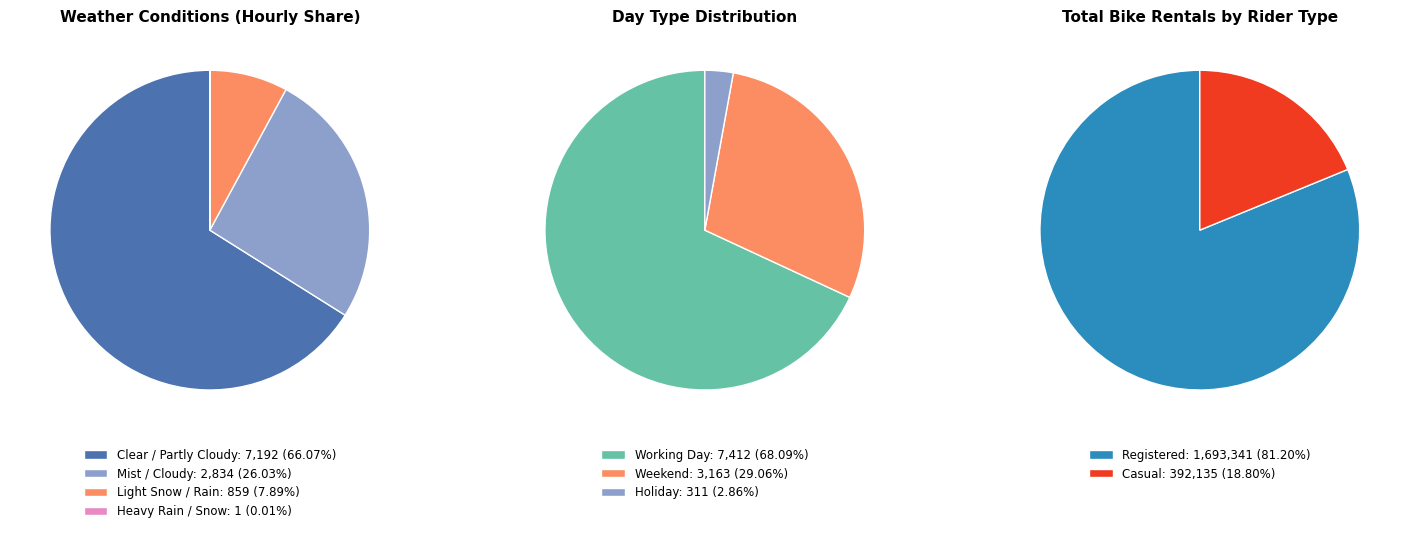

In [12]:
# Pie charts for Weather Conditions, Day Type, and Total Rider Share
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

pie_configs = [
    (
        "Weather Conditions (Hourly Share)",
        df_bikes["weather_label"].value_counts().reindex(df_bikes["weather_label"].cat.categories),
        ["#4C72B0", "#8DA0CB", "#FC8D62", "#E78AC3"],
    ),
    (
        "Day Type Distribution",
        df_bikes["day_type"].value_counts().reindex(df_bikes["day_type"].cat.categories),
        ["#66C2A5", "#FC8D62", "#8DA0CB"],
    ),
    (
        "Total Bike Rentals by Rider Type",
        pd.Series({"Registered": df_bikes["registered"].sum(), "Casual": df_bikes["casual"].sum()}),
        ["#2B8CBE", "#F03B20"],
    ),
]

# Loop through pie configurations; use clean legends to prevent overlapping text on tiny slices
for ax, (title, series, colors) in zip(axes, pie_configs):
    total = series.sum()
    wedges, _ = ax.pie(series.values, colors=colors, startangle=90, wedgeprops=dict(edgecolor="white"))
    legend_labels = [f"{lbl}: {val:,} ({val / total * 100:.2f}%)" for lbl, val in zip(series.index, series.values)]
    ax.set_title(title, fontsize=11, fontweight="bold")
    ax.legend(wedges, legend_labels, loc="upper center", bbox_to_anchor=(0.5, -0.02), fontsize=8.5, frameon=False)

plt.tight_layout()
plt.show()

### Categorical Analysis Takeaways
* **Balanced sampling across time:** Seasons and days of the week are evenly sampled (~25% per season, ~14.3% per weekday), so seasonal or weekday differences in Section 7 are not artifacts of unequal sample sizes.
* **Fair weather dominates:** **66.07%** of hours are Clear/Partly Cloudy, **26.03%** are Mist/Cloudy, **7.89%** involve Light Snow/Rain, and only **1 hour (0.01%)** involves Heavy Rain/Snow.
* **Commuter base:** Out of **2,085,476 total bike rentals** in the dataset, **81.20%** come from `Registered` subscribers and **18.80%** from `Casual` riders.

## Section 7: Grouped Analysis

We now group the data by `season_label`, `weather_label`, `day_type`, and `day_of_week` using reusable aggregation functions, plus a multi-variable `groupby` (`season_label` × `day_type`) and a `pd.pivot_table` (`hour` × `day_type`) to uncover how rider segments behave under different conditions.

In [13]:
def grouped_summary(df, group_col, target_col="count"):
    """Compute count, mean, median, std, min, and max of target_col grouped by group_col."""
    summary = (
        df.groupby(group_col, observed=True)[target_col]
        .agg(["count", "mean", "median", "std", "min", "max"])
        .round(2)
    )
    return summary


for g_col in ["season_label", "weather_label", "day_type", "day_of_week"]:
    print(f"\n--- Grouped Summary of Hourly Rentals (count) by {g_col} ---")
    display(grouped_summary(df_bikes, g_col))


--- Grouped Summary of Hourly Rentals (count) by season_label ---


,count,mean,median,std,min,max
season_label,,,,,,
Q1: Winter (Jan-Mar),2686,116.34,78.0,125.27,1,801
Q2: Spring (Apr-Jun),2733,215.25,172.0,192.01,1,873
Q3: Summer (Jul-Sep),2733,234.42,195.0,197.15,1,977
Q4: Fall (Oct-Dec),2734,198.99,161.0,177.62,1,948



--- Grouped Summary of Hourly Rentals (count) by weather_label ---


,count,mean,median,std,min,max
weather_label,,,,,,
Clear / Partly Cloudy,7192,205.24,161.0,187.96,1,977
Mist / Cloudy,2834,178.96,134.0,168.37,1,890
Light Snow / Rain,859,118.85,71.0,138.58,1,891
Heavy Rain / Snow,1,164.00,164.0,NaN,164,164



--- Grouped Summary of Hourly Rentals (count) by day_type ---


,count,mean,median,std,min,max
day_type,,,,,,
Working Day,7412,193.01,151.0,184.51,1,977
Weekend,3163,188.77,128.0,174.27,1,783
Holiday,311,185.88,133.0,168.30,1,712



--- Grouped Summary of Hourly Rentals (count) by day_of_week ---


,count,mean,median,std,min,max
day_of_week,,,,,,
Monday,1551,190.39,146.0,180.94,1,968
Tuesday,1539,189.72,146.0,186.72,1,970
Wednesday,1551,188.41,136.0,190.94,1,977
Thursday,1553,197.30,155.0,187.61,1,901
Friday,1529,197.84,167.0,172.52,1,900
Saturday,1584,196.67,141.5,180.92,1,783
Sunday,1579,180.84,119.0,167.02,1,757


In [14]:
# Multi-column groupby: average casual, registered, and total rentals by Season x Day Type
multi_group = (
    df_bikes.groupby(["season_label", "day_type"], observed=True)[["casual", "registered", "count"]]
    .mean()
    .round(1)
)
print("--- Multi-Group Mean Rentals: Season x Day Type ---")
display(multi_group)

# New technique (beyond class homework): pd.pivot_table comparing hourly demand across Day Types
hourly_pivot = pd.pivot_table(
    df_bikes,
    values="count",
    index="hour",
    columns="day_type",
    aggfunc="mean",
    observed=True,
).round(1)
print("\n--- Pivot Table (Selected Hours): Mean Rentals by Hour x Day Type ---")
display(hourly_pivot.loc[[0, 4, 8, 12, 15, 17, 18, 21]])

--- Multi-Group Mean Rentals: Season x Day Type ---


casual  registered  count
season_label         day_type                              
Q1: Winter (Jan-Mar) Working Day    10.3       111.1  121.3
                     Weekend        28.3        80.3  108.6
                     Holiday         8.1        65.8   73.9
Q2: Spring (Apr-Jun) Working Day    33.1       178.9  211.9
                     Weekend        82.4       141.8  224.2
                     Holiday        38.3       159.5  197.8
Q3: Summer (Jul-Sep) Working Day    37.8       197.6  235.3
                     Weekend        81.1       150.8  231.9
                     Holiday        92.0       145.9  237.8
Q4: Fall (Oct-Dec)   Working Day    19.0       183.3  202.3
                     Weekend        49.4       140.4  189.9
                     Holiday        40.9       169.9  210.8


--- Pivot Table (Selected Hours): Mean Rentals by Hour x Day Type ---


day_type,Working Day,Weekend,Holiday
hour,,,
0,36.7,97.2,66.8
4,5.4,8.7,7.4
8,479.9,100.8,229.0
12,199.3,385.1,318.4
15,198.6,381.7,292.8
17,529.2,336.3,368.0
18,495.5,287.1,344.5
21,184.9,145.5,181.8


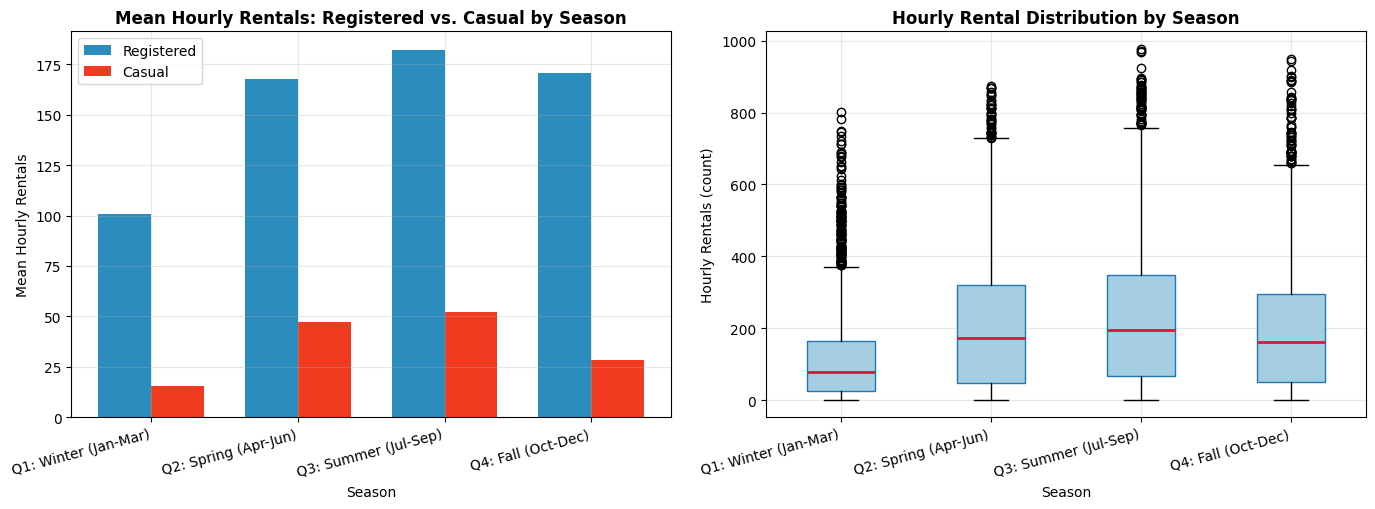

In [15]:
# Visualize grouped comparisons:
# Left: Casual vs Registered mean rentals by Season; Right: Total count boxplot by Season
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.2))

season_rider_means = (
    df_bikes.groupby("season_label", observed=True)[["casual", "registered"]]
    .mean()
)
x = np.arange(len(season_rider_means))
width = 0.36

ax1.bar(x - width / 2, season_rider_means["registered"], width, label="Registered", color="#2B8CBE")
ax1.bar(x + width / 2, season_rider_means["casual"], width, label="Casual", color="#F03B20")
ax1.set_title("Mean Hourly Rentals: Registered vs. Casual by Season", fontsize=12, fontweight="bold")
ax1.set_xlabel("Season")
ax1.set_ylabel("Mean Hourly Rentals")
ax1.set_xticks(x)
ax1.set_xticklabels(season_rider_means.index, rotation=15, ha="right")
ax1.legend()

season_cats = list(df_bikes["season_label"].cat.categories)
season_arrays = [df_bikes.loc[df_bikes["season_label"] == s, "count"].values for s in season_cats]
ax2.boxplot(season_arrays, patch_artist=True,
            boxprops=dict(facecolor="#A6CEE3", color="#1F78B4"),
            medianprops=dict(color="crimson", linewidth=2))
ax2.set_title("Hourly Rental Distribution by Season", fontsize=12, fontweight="bold")
ax2.set_xlabel("Season")
ax2.set_ylabel("Hourly Rentals (count)")
ax2.set_xticks(range(1, len(season_cats) + 1))
ax2.set_xticklabels(season_cats, rotation=15, ha="right")

plt.tight_layout()
plt.show()

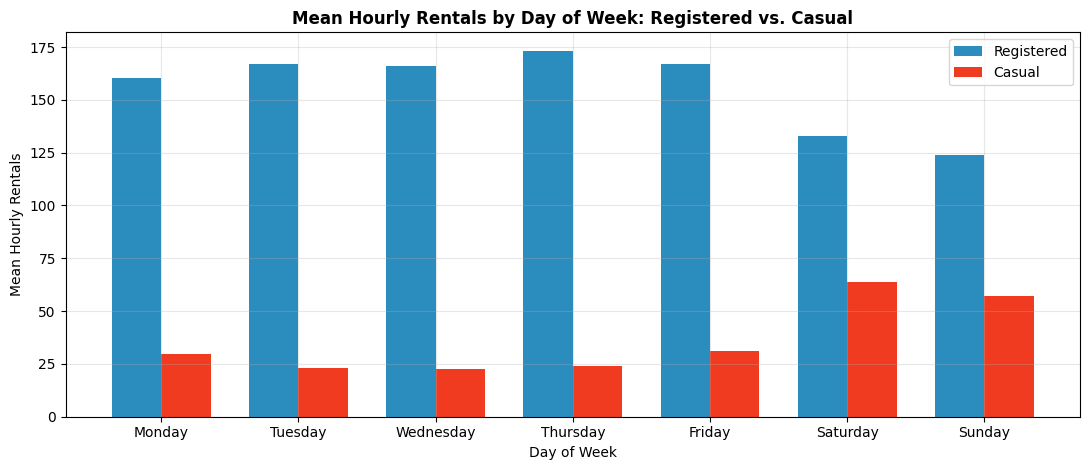

In [16]:
# Grouped bar chart: Mean Casual vs Registered rentals by Day of Week
dow_means = df_bikes.groupby("day_of_week", observed=True)[["casual", "registered"]].mean()
x_dow = np.arange(len(dow_means))

fig, ax = plt.subplots(figsize=(11, 4.8))
ax.bar(x_dow - width / 2, dow_means["registered"], width, label="Registered", color="#2B8CBE")
ax.bar(x_dow + width / 2, dow_means["casual"], width, label="Casual", color="#F03B20")
ax.set_title("Mean Hourly Rentals by Day of Week: Registered vs. Casual", fontsize=12, fontweight="bold")
ax.set_xlabel("Day of Week")
ax.set_ylabel("Mean Hourly Rentals")
ax.set_xticks(x_dow)
ax.set_xticklabels(dow_means.index)
ax.legend()
plt.tight_layout()
plt.show()

### Grouped Analysis Insights
* **Strong seasonal gradient:** Average hourly rentals peak in **Q3 Summer (234.4/hr)** and **Q2 Spring (215.3/hr)**, remain strong in **Q4 Fall (199.0/hr)**, and drop sharply in **Q1 Winter (116.3/hr)**.
* **Weather penalty:** Average demand falls from **205.2/hr** in Clear/Partly Cloudy weather to **179.0/hr** in Mist/Cloudy weather and **118.8/hr** in Light Snow/Rain (−42% vs. clear weather).
* **Striking commuter vs. leisure split:** Total mean rentals are remarkably similar across Working Days (193.0/hr), Weekends (188.8/hr), and Holidays (185.9/hr)—*but the rider mix flips!* Registered riders dominate Monday–Friday (~167.9/hr vs. ~25.1 casual/hr), whereas **Casual ridership more than doubles on Saturday (63.6/hr) and Sunday (57.1/hr)** while Registered usage drops (~123.8–133.0/hr).

## Section 8: New Feature Engineering

To deepen the analysis, we create four meaningful new features:
1. **`casual_ratio`** (`casual / count`): The fraction of hourly rentals made by casual (non-subscriber) riders. This measures whether an hour's demand is driven by commuters or recreational riders.
2. **`temp_diff`** (`atemp - temp`): The gap between "feels-like" apparent temperature and actual air temperature.
3. **`count_vs_2011_pct`** (`count / mean_2011 * 100`): A standardized demand index expressed as a percentage of the 2011 baseline mean (`144.22` rentals/hr), making year-over-year growth immediately interpretable.
4. **`temp_band`** (created with `pd.cut`, a pandas binning technique beyond class homework): Groups continuous temperatures into four human-interpretable comfort bands (`Cold (<10°C)`, `Mild (10-20°C)`, `Warm (20-30°C)`, `Hot (>30°C)`).

In [17]:
# 1. Ratio of casual riders to total hourly rentals (safe since count >= 1 everywhere)
df_bikes["casual_ratio"] = df_bikes["casual"] / df_bikes["count"]

# 2. Apparent temperature difference ("feels like" minus actual air temperature)
df_bikes["temp_diff"] = df_bikes["atemp"] - df_bikes["temp"]

# 3. Standardized demand index relative to the 2011 baseline average (= 100)
base_2011_mean = df_bikes.loc[df_bikes["year"] == 2011, "count"].mean()
df_bikes["count_vs_2011_pct"] = (df_bikes["count"] / base_2011_mean) * 100.0

# 4. New pandas technique: bin temperature into comfort bands using pd.cut
df_bikes["temp_band"] = pd.cut(
    df_bikes["temp"],
    bins=[0, 10, 20, 30, 45],
    labels=["Cold (<10°C)", "Mild (10-20°C)", "Warm (20-30°C)", "Hot (>30°C)"],
    include_lowest=True,
)

# Summarize engineered features across Temperature Bands and Day Types
band_summary = df_bikes.groupby("temp_band", observed=True).agg(
    hours=("count", "size"),
    mean_count=("count", "mean"),
    mean_casual_ratio=("casual_ratio", "mean"),
    mean_index_vs_2011=("count_vs_2011_pct", "mean"),
).round(3)
print(f"2011 Baseline Mean Hourly Rentals: {base_2011_mean:.2f} (= 100.0 index)")
display(band_summary)

daytype_ratio = df_bikes.groupby("day_type", observed=True)[["casual_ratio", "count_vs_2011_pct"]].mean().round(3)
display(daytype_ratio)

2011 Baseline Mean Hourly Rentals: 144.22 (= 100.0 index)


,hours,mean_count,mean_casual_ratio,mean_index_vs_2011
temp_band,,,,
Cold (<10°C),1259,73.186,0.071,50.745
Mild (10-20°C),4049,150.465,0.139,104.328
Warm (20-30°C),4334,223.411,0.205,154.907
Hot (>30°C),1244,334.274,0.258,231.775


,casual_ratio,count_vs_2011_pct
day_type,,
Working Day,0.136,133.828
Weekend,0.248,130.884
Holiday,0.218,128.882


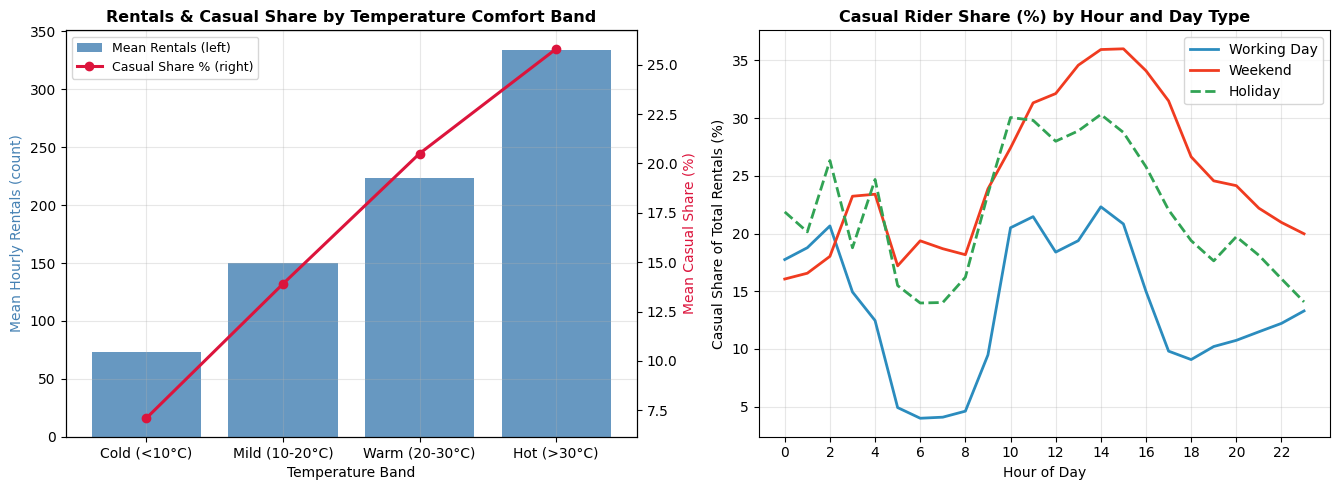

In [18]:
# Visualize engineered features:
# Left: Mean Rentals & Casual Share across Temperature Comfort Bands
# Right: Hourly Casual Rider Share by Day Type (Working Day vs Weekend/Holiday)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.5, 5))

band_labels = band_summary.index.astype(str)
ax1_twin = ax1.twinx()
bars = ax1.bar(band_labels, band_summary["mean_count"], color="steelblue", alpha=0.82, label="Mean Rentals (left)")
line = ax1_twin.plot(band_labels, band_summary["mean_casual_ratio"] * 100, color="crimson",
                     marker="o", linewidth=2.2, label="Casual Share % (right)")
ax1.set_title("Rentals & Casual Share by Temperature Comfort Band", fontsize=11.5, fontweight="bold")
ax1.set_xlabel("Temperature Band")
ax1.set_ylabel("Mean Hourly Rentals (count)", color="steelblue")
ax1_twin.set_ylabel("Mean Casual Share (%)", color="crimson")
ax1_twin.grid(False)

# Combine legends from twin axes cleanly
h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax1_twin.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper left", fontsize=9)

# Hourly casual ratio across day types
hourly_casual_ratio = (
    df_bikes.groupby(["hour", "day_type"], observed=True)["casual_ratio"]
    .mean()
    .unstack() * 100
)
for col, color, style in [("Working Day", "#2B8CBE", "-"), ("Weekend", "#F03B20", "-"), ("Holiday", "#31A354", "--")]:
    ax2.plot(hourly_casual_ratio.index, hourly_casual_ratio[col], label=col, color=color, linestyle=style, linewidth=2)

ax2.set_title("Casual Rider Share (%) by Hour and Day Type", fontsize=11.5, fontweight="bold")
ax2.set_xlabel("Hour of Day")
ax2.set_ylabel("Casual Share of Total Rentals (%)")
ax2.set_xticks(range(0, 24, 2))
ax2.legend()

plt.tight_layout()
plt.show()

### Feature Engineering Takeaways
* **Temperature boosts both volume and leisure share:** Moving from `Cold (<10°C)` to `Hot (>30°C)` more than quadruples average hourly rentals (**73.2 → 334.3**) and increases the casual rider share from **7.1% to 25.8%**.
* **Midday recreational window:** `casual_ratio` peaks between **11 AM and 4 PM** on every day type, reaching **~31–36% on weekends** vs. only **~15–22% on working days**, confirming that weekday midday riders include more subscribers while weekend afternoons are heavily recreational.

## Section 9: Trends Over Time

To examine temporal dynamics across multiple time scales, we plot:
1. **Monthly & 7-Day Rolling Trends (2011–2012):** Showing seasonal cycles and growth from 2011 to 2012 (using `.rolling(window=7).mean()`, an advanced pandas time-series smoothing technique).
2. **Standardized Monthly Time Series (Z-Scores):** Plotting standardized `count`, `temp`, and `humidity` on the same scale so variables with very different units can be directly compared over time.
3. **Hourly Commuter vs. Weekend Curves:** Comparing `casual` and `registered` hourly profiles on Working Days vs. Weekends/Holidays.

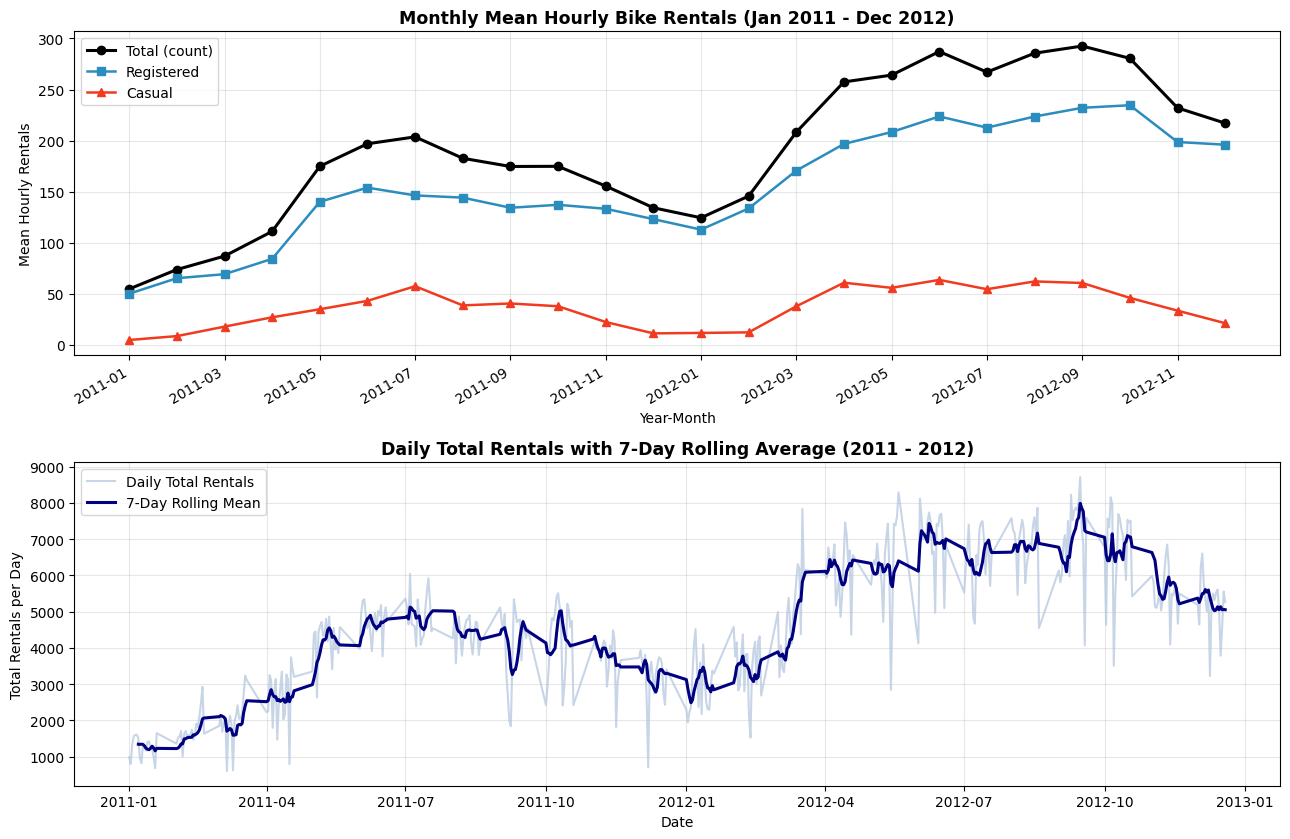

In [19]:
# Aggregate to monthly averages and daily totals
monthly_df = df_bikes.groupby("year_month").agg(
    count=("count", "mean"),
    registered=("registered", "mean"),
    casual=("casual", "mean"),
    temp=("temp", "mean"),
    humidity=("humidity", "mean"),
).reset_index()

daily_df = df_bikes.groupby("date").agg(
    daily_count=("count", "sum"),
    mean_temp=("temp", "mean"),
).reset_index()
daily_df["date"] = pd.to_datetime(daily_df["date"])
daily_df["rolling_7d_count"] = daily_df["daily_count"].rolling(window=7).mean()

# Chart 1: Monthly average hourly rentals + 7-day rolling daily total
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 8.5))

x_m = np.arange(len(monthly_df))
ax1.plot(x_m, monthly_df["count"], marker="o", linewidth=2.2, color="black", label="Total (count)")
ax1.plot(x_m, monthly_df["registered"], marker="s", linewidth=1.8, color="#2B8CBE", label="Registered")
ax1.plot(x_m, monthly_df["casual"], marker="^", linewidth=1.8, color="#F03B20", label="Casual")
ax1.set_title("Monthly Mean Hourly Bike Rentals (Jan 2011 - Dec 2012)", fontsize=12.5, fontweight="bold")
ax1.set_xlabel("Year-Month")
ax1.set_ylabel("Mean Hourly Rentals")
ax1.set_xticks(x_m[::2])
ax1.set_xticklabels(monthly_df["year_month"].iloc[::2], rotation=30, ha="right")
ax1.legend()

ax2.plot(daily_df["date"], daily_df["daily_count"], color="lightsteelblue", alpha=0.7, label="Daily Total Rentals")
ax2.plot(daily_df["date"], daily_df["rolling_7d_count"], color="navy", linewidth=2.2, label="7-Day Rolling Mean")
ax2.set_title("Daily Total Rentals with 7-Day Rolling Average (2011 - 2012)", fontsize=12.5, fontweight="bold")
ax2.set_xlabel("Date")
ax2.set_ylabel("Total Rentals per Day")
ax2.legend()

plt.tight_layout()
plt.show()

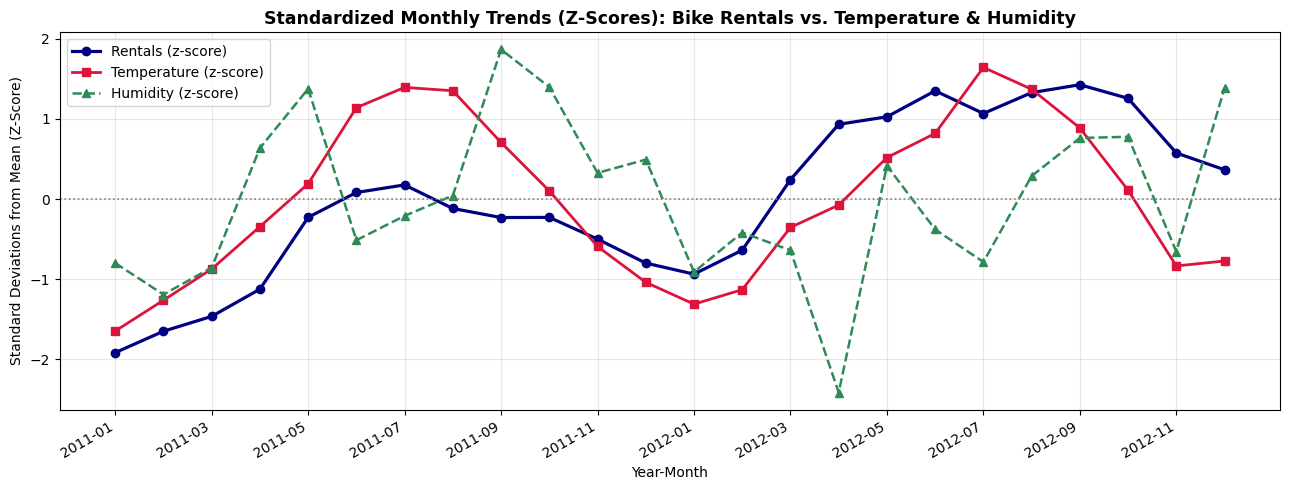

In [20]:
# Standardize monthly count, temp, and humidity via z-scores: (x - mean) / std
for col in ["count", "temp", "humidity"]:
    monthly_df[f"{col}_z"] = (monthly_df[col] - monthly_df[col].mean()) / monthly_df[col].std()

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(x_m, monthly_df["count_z"], marker="o", linewidth=2.3, color="navy", label="Rentals (z-score)")
ax.plot(x_m, monthly_df["temp_z"], marker="s", linewidth=2.0, color="crimson", label="Temperature (z-score)")
ax.plot(x_m, monthly_df["humidity_z"], marker="^", linewidth=1.8, linestyle="--", color="seagreen", label="Humidity (z-score)")
ax.axhline(0, color="gray", linestyle=":", linewidth=1.2)
ax.set_title("Standardized Monthly Trends (Z-Scores): Bike Rentals vs. Temperature & Humidity", fontsize=12.5, fontweight="bold")
ax.set_xlabel("Year-Month")
ax.set_ylabel("Standard Deviations from Mean (Z-Score)")
ax.set_xticks(x_m[::2])
ax.set_xticklabels(monthly_df["year_month"].iloc[::2], rotation=30, ha="right")
ax.legend()
plt.tight_layout()
plt.show()

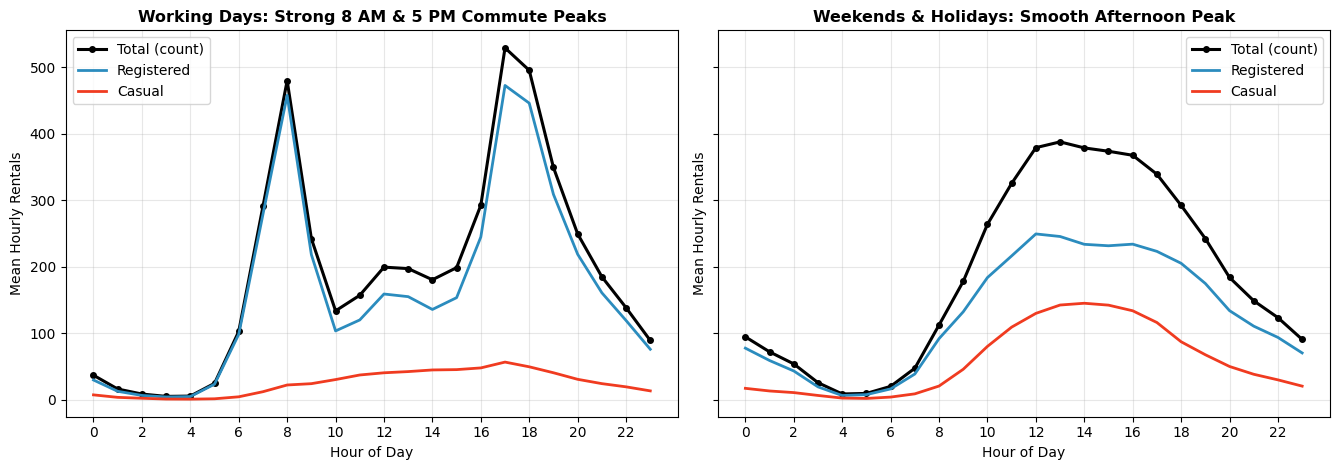

In [21]:
# Hourly profile comparing Working Days vs Non-Working Days (Weekends/Holidays)
hourly_working = (
    df_bikes.groupby(["workingday", "hour"])[["registered", "casual", "count"]]
    .mean()
)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.5, 4.8), sharey=True)

for ax, wd_val, title in [
    (ax1, 1, "Working Days: Strong 8 AM & 5 PM Commute Peaks"),
    (ax2, 0, "Weekends & Holidays: Smooth Afternoon Peak"),
]:
    sub = hourly_working.loc[wd_val]
    ax.plot(sub.index, sub["count"], marker="o", markersize=4, linewidth=2.2, color="black", label="Total (count)")
    ax.plot(sub.index, sub["registered"], linewidth=2.0, color="#2B8CBE", label="Registered")
    ax.plot(sub.index, sub["casual"], linewidth=2.0, color="#F03B20", label="Casual")
    ax.set_title(title, fontsize=11.5, fontweight="bold")
    ax.set_xlabel("Hour of Day")
    ax.set_ylabel("Mean Hourly Rentals")
    ax.set_xticks(range(0, 24, 2))
    ax.legend()

plt.tight_layout()
plt.show()

### Time-Trend Insights
* **Strong system growth:** Monthly average rentals climbed substantially from 2011 (`144.2/hr`) to 2012 (`238.6/hr`, a **+65.4% increase**), reflecting growing bikeshare adoption.
* **Tight co-movement with temperature:** On the standardized z-score chart, bike rentals rise and fall nearly in lockstep with seasonal temperature waves—while sitting slightly higher in 2012 than in 2011 due to the underlying growth trend.
* **Commuter vs. leisure hourly shapes:** On working days, `registered` users create sharp rush-hour peaks at **8 AM** and **5–6 PM**; on weekends/holidays, total demand forms a single smooth bell peaking between **12 PM and 4 PM**.

## Section 10: Variable Relationships

In this section, we examine relationships across numerical features using:
1. **Correlation and covariance matrices**, visualized with a custom **annotated correlation heatmap** (`plt.imshow` + cell text labels, beyond basic class plots).
2. **Random sampling analysis:** Drawing a reproducible random sample of `n = 1,000` observations from the full 10,886-row dataset, verifying how closely sample statistics match the population, and creating uncluttered scatter plots from the sample.

In [22]:
rel_cols = ["temp", "atemp", "humidity", "windspeed", "weather", "hour", "workingday", "year", "casual", "registered", "count", "casual_ratio"]
corr_matrix = df_bikes[rel_cols].corr()
cov_matrix = df_bikes[["temp", "humidity", "windspeed", "casual", "registered", "count"]].cov().round(2)

print("--- Covariance Matrix (Key Numerical Variables) ---")
display(cov_matrix)
print("\n--- Correlation with Total Hourly Rentals (count) ---")
display(corr_matrix["count"].sort_values(ascending=False).round(3).to_frame("corr_with_count"))

--- Covariance Matrix (Key Numerical Variables) ---


,temp,humidity,windspeed,casual,registered,count
temp,60.71,-9.74,-1.14,181.83,374.91,556.73
humidity,-9.74,370.37,-50.06,-334.78,-771.62,-1106.40
windspeed,-1.14,-50.06,66.66,37.64,112.28,149.92
casual,181.83,-334.78,37.64,2496.05,3752.24,6248.29
registered,374.91,-771.62,112.28,3752.24,22812.79,26565.03
count,556.73,-1106.40,149.92,6248.29,26565.03,32813.31



--- Correlation with Total Hourly Rentals (count) ---


,corr_with_count
count,1.000
registered,0.971
casual,0.690
hour,0.401
temp,0.394
atemp,0.390
year,0.260
casual_ratio,0.131
windspeed,0.101
workingday,0.012


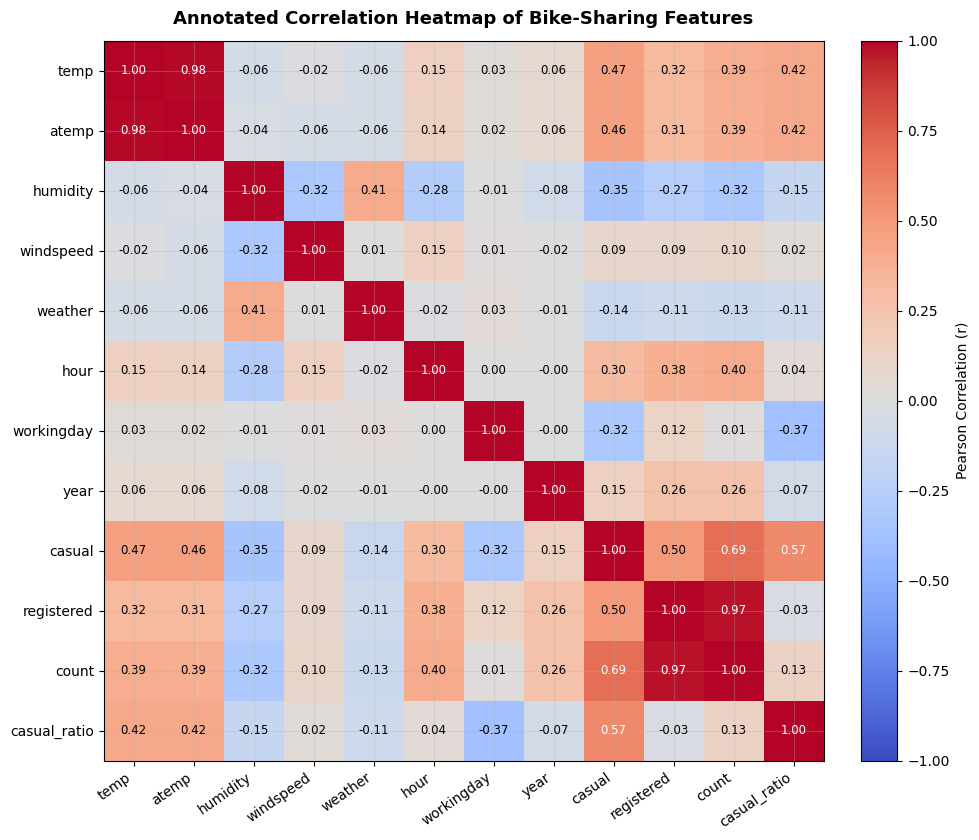

In [23]:
# New matplotlib technique: Annotated correlation heatmap using imshow + colorbar + cell text
fig, ax = plt.subplots(figsize=(10.5, 8.5))
im = ax.imshow(corr_matrix.values, cmap="coolwarm", vmin=-1, vmax=1)
cbar = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label("Pearson Correlation (r)")

ax.set_xticks(np.arange(len(rel_cols)))
ax.set_yticks(np.arange(len(rel_cols)))
ax.set_xticklabels(rel_cols, rotation=35, ha="right")
ax.set_yticklabels(rel_cols)
ax.set_title("Annotated Correlation Heatmap of Bike-Sharing Features", fontsize=13, fontweight="bold", pad=12)

# Annotate each cell with its correlation coefficient, adjusting text color for contrast
for i in range(len(rel_cols)):
    for j in range(len(rel_cols)):
        val = corr_matrix.values[i, j]
        txt_color = "white" if abs(val) > 0.55 else "black"
        ax.text(j, i, f"{val:.2f}", ha="center", va="center", color=txt_color, fontsize=8.5)

plt.tight_layout()
plt.show()

In [24]:
# Obtain and analyze a reproducible random sample (n = 1,000) from the 10,886-row dataset
df_sample = df_bikes.sample(n=1000, random_state=42)

sample_comparison = pd.DataFrame({
    "Full Data Mean (N=10,886)": df_bikes[["temp", "humidity", "windspeed", "count", "casual_ratio"]].mean(),
    "Sample Mean (n=1,000)": df_sample[["temp", "humidity", "windspeed", "count", "casual_ratio"]].mean(),
    "Full Data Std": df_bikes[["temp", "humidity", "windspeed", "count", "casual_ratio"]].std(),
    "Sample Std": df_sample[["temp", "humidity", "windspeed", "count", "casual_ratio"]].std(),
}).round(3)
print("--- Full Dataset vs. Random Sample (n = 1,000) Comparison ---")
display(sample_comparison)
print(f"Sample corr(temp, count): {df_sample['temp'].corr(df_sample['count']):.3f} vs. Full corr: {df_bikes['temp'].corr(df_bikes['count']):.3f}")

--- Full Dataset vs. Random Sample (n = 1,000) Comparison ---


,"Full Data Mean (N=10,886)","Sample Mean (n=1,000)",Full Data Std,Sample Std
temp,20.231,20.092,7.792,7.813
humidity,61.886,62.189,19.245,18.785
windspeed,12.799,12.882,8.165,8.056
count,191.574,191.126,181.144,182.088
casual_ratio,0.171,0.171,0.137,0.137


Sample corr(temp, count): 0.400 vs. Full corr: 0.394


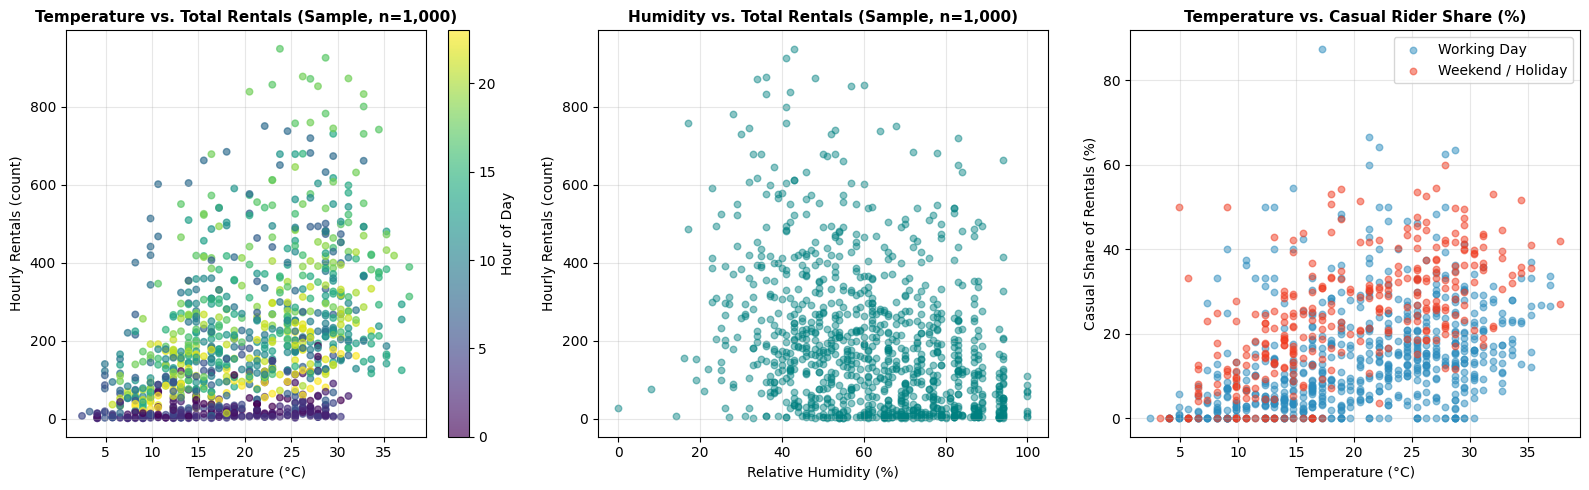

In [25]:
# Scatter plots using the 1,000-row sample so individual points remain legible
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# 1. Temp vs Count (colored by hour of day)
sc1 = axes[0].scatter(df_sample["temp"], df_sample["count"], c=df_sample["hour"],
                      cmap="viridis", alpha=0.65, s=22)
plt.colorbar(sc1, ax=axes[0], label="Hour of Day")
axes[0].set_title("Temperature vs. Total Rentals (Sample, n=1,000)", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Temperature (°C)")
axes[0].set_ylabel("Hourly Rentals (count)")

# 2. Humidity vs Count
axes[1].scatter(df_sample["humidity"], df_sample["count"], color="teal", alpha=0.45, s=22)
axes[1].set_title("Humidity vs. Total Rentals (Sample, n=1,000)", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Relative Humidity (%)")
axes[1].set_ylabel("Hourly Rentals (count)")

# 3. Temp vs Casual Ratio separated by Working Day vs Non-Working Day
for wd, color, label in [(1, "#2B8CBE", "Working Day"), (0, "#F03B20", "Weekend / Holiday")]:
    sub = df_sample[df_sample["workingday"] == wd]
    axes[2].scatter(sub["temp"], sub["casual_ratio"] * 100, color=color, alpha=0.5, s=22, label=label)
axes[2].set_title("Temperature vs. Casual Rider Share (%)", fontsize=11, fontweight="bold")
axes[2].set_xlabel("Temperature (°C)")
axes[2].set_ylabel("Casual Share of Rentals (%)")
axes[2].legend()

plt.tight_layout()
plt.show()

### Variable Relationship Takeaways
* **Strongest non-component predictors of `count`:** `hour` (`r = 0.401`), `temp` (`r = 0.394`), and `atemp` (`r = 0.390`) show the strongest positive correlations with total rentals, while `humidity` (`r = -0.317`) and `weather` (`r = -0.129`) are negatively correlated.
* **Multicollinearity note:** `temp` and `atemp` are nearly identical (`r = 0.985`), and `registered`/`casual` are components of `count`, so only independent weather/calendar predictors should be used when modeling `count`.
* **Sample representativeness:** The 1,000-row random sample closely matches the full dataset's means, standard deviations, and `temp`–`count` correlation (**0.400** vs. **0.394**), making it a reliable visual proxy.

## Section 11: Hypothesis

Based on our exploratory findings and domain reasoning about outdoor transportation, we state two formal hypotheses:

* **Primary Hypothesis ($H_1$):** Higher ambient temperature (`temp`) has a positive linear relationship with total hourly bike rentals (`count`). **Reasoning:** Cycling is an exposed outdoor activity; warmer temperatures increase rider comfort and make both discretionary leisure trips and bike-commuting trips more appealing than walking or driving, whereas cold weather discourages riding.
* **Secondary Hypothesis ($H_2$):** A multiple linear regression model combining temperature with additional weather and calendar predictors (`humidity`, `windspeed`, `hour`, `workingday`, `year`) will explain substantially more variance ($R^2$) in `count` than temperature alone, because hourly demand also depends heavily on time of day, moisture/rain comfort (`humidity`), and multi-year system growth (`year`).

## Section 12: Linear Regression with `sklearn`

We test both hypotheses using `sklearn.linear_model.LinearRegression`. To evaluate generalization fairly, we split the dataset into **80% training (`8,708` rows)** and **20% test (`2,178` rows)** sets with `random_state=42`.

* **Model 1 (Simple Linear Regression):** Predicts `count` from `temp` alone, allowing us to directly plot the fitted regression line and predicted-vs-actual values.
* **Model 2 (Multiple Linear Regression):** Predicts `count` from `['temp', 'humidity', 'windspeed', 'hour', 'workingday', 'year']`, followed by a predicted-vs-actual comparison and a residual diagnostic plot.

In [26]:
def evaluate_regression(model, X_train, X_test, y_train, y_test, model_name):
    """Fit a linear regression model and return evaluation metrics and test predictions."""
    model.fit(X_train, y_train)
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    metrics = {
        "Model": model_name,
        "Train R^2": round(r2_score(y_train, train_pred), 4),
        "Test R^2": round(r2_score(y_test, test_pred), 4),
        "Test RMSE": round(np.sqrt(mean_squared_error(y_test, test_pred)), 2),
        "Test MAE": round(mean_absolute_error(y_test, test_pred), 2),
    }
    return model, test_pred, metrics


# Prepare train/test split using consistent indices for fair model comparison
y = df_bikes["count"]
multi_features = ["temp", "humidity", "windspeed", "hour", "workingday", "year"]
X_train_all, X_test_all, y_train, y_test = train_test_split(
    df_bikes[multi_features], y, test_size=0.20, random_state=42
)

# Model 1: Simple Linear Regression (temp -> count)
simple_model, y_pred_simple, metrics_simple = evaluate_regression(
    LinearRegression(),
    X_train_all[["temp"]],
    X_test_all[["temp"]],
    y_train,
    y_test,
    "Simple LR (temp only)",
)

# Model 2: Multiple Linear Regression (6 weather + calendar features -> count)
multi_model, y_pred_multi, metrics_multi = evaluate_regression(
    LinearRegression(),
    X_train_all,
    X_test_all,
    y_train,
    y_test,
    "Multiple LR (6 features)",
)

print(f"Simple LR equation: count = {simple_model.intercept_:.2f} + {simple_model.coef_[0]:.2f} * temp")
display(pd.DataFrame([metrics_simple, metrics_multi]).set_index("Model"))

coef_df = pd.DataFrame({
    "Feature": multi_features,
    "Coefficient": np.round(multi_model.coef_, 3),
})
print(f"\nMultiple LR Intercept: {multi_model.intercept_:.2f}")
display(coef_df)

Simple LR equation: count = 7.86 + 9.06 * temp


,Train R^2,Test R^2,Test RMSE,Test MAE
Model,,,,
Simple LR (temp only),0.1521,0.1693,165.59,125.15
Multiple LR (6 features),0.3666,0.3785,143.22,106.29



Multiple LR Intercept: -164798.04


,Feature,Coefficient
0,temp,7.420
1,humidity,-1.820
2,windspeed,0.031
3,hour,7.911
4,workingday,1.050
5,year,81.958


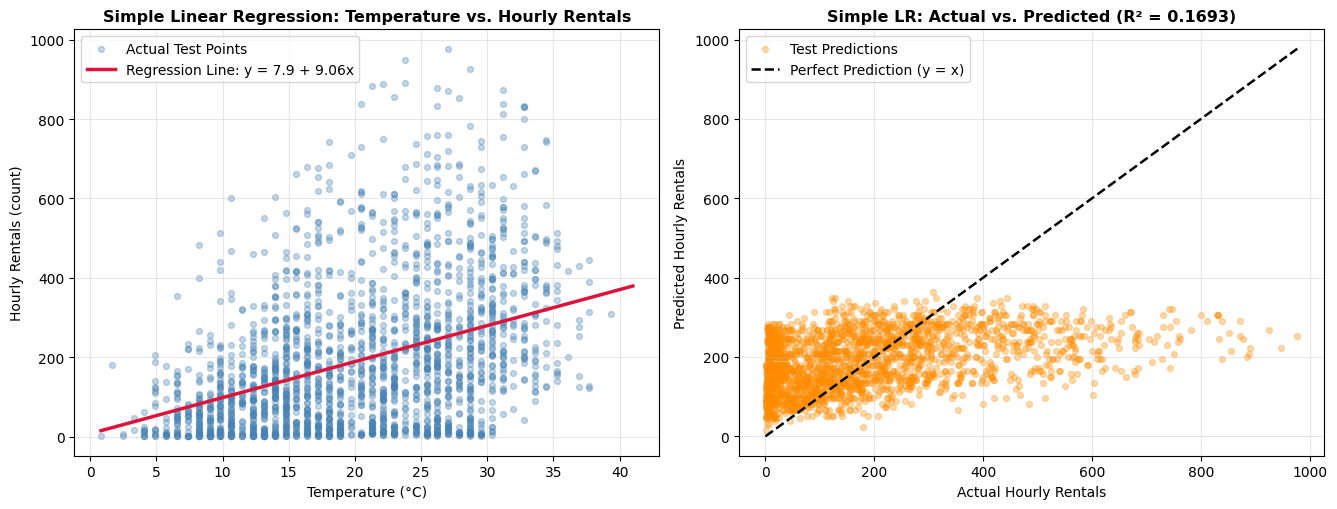

In [27]:
# Plots for Model 1 (Simple Linear Regression):
# Left: Scatter of Temp vs Count (Test Set) with Fitted Regression Line
# Right: Predicted vs. Actual Values
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.5, 5.2))

x_vals = np.linspace(df_bikes["temp"].min(), df_bikes["temp"].max(), 100).reshape(-1, 1)
y_line = simple_model.predict(pd.DataFrame(x_vals, columns=["temp"]))

ax1.scatter(X_test_all["temp"], y_test, alpha=0.32, s=18, color="steelblue", label="Actual Test Points")
ax1.plot(x_vals, y_line, color="crimson", linewidth=2.5,
         label=f"Regression Line: y = {simple_model.intercept_:.1f} + {simple_model.coef_[0]:.2f}x")
ax1.set_title("Simple Linear Regression: Temperature vs. Hourly Rentals", fontsize=11.5, fontweight="bold")
ax1.set_xlabel("Temperature (°C)")
ax1.set_ylabel("Hourly Rentals (count)")
ax1.legend()

ax2.scatter(y_test, y_pred_simple, alpha=0.32, s=18, color="darkorange", label="Test Predictions")
lims = [0, max(y_test.max(), y_pred_simple.max())]
ax2.plot(lims, lims, "k--", linewidth=1.8, label="Perfect Prediction (y = x)")
ax2.set_title(f"Simple LR: Actual vs. Predicted (R² = {metrics_simple['Test R^2']})", fontsize=11.5, fontweight="bold")
ax2.set_xlabel("Actual Hourly Rentals")
ax2.set_ylabel("Predicted Hourly Rentals")
ax2.legend()

plt.tight_layout()
plt.show()

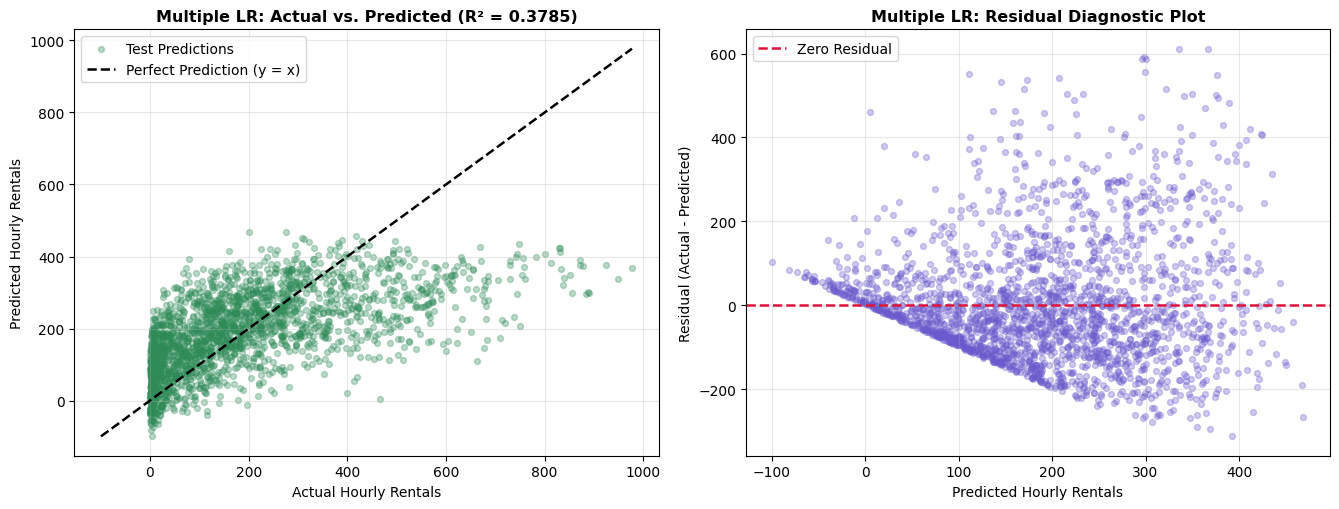

In [28]:
# Plots for Model 2 (Multiple Linear Regression):
# Left: Actual vs. Predicted with Reference Line
# Right: Residual Diagnostic Plot (beyond-class model diagnostic skill)
residuals_multi = y_test - y_pred_multi

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.5, 5.2))

ax1.scatter(y_test, y_pred_multi, alpha=0.32, s=18, color="seagreen", label="Test Predictions")
lims_m = [min(0, y_pred_multi.min()), y_test.max()]
ax1.plot(lims_m, lims_m, "k--", linewidth=1.8, label="Perfect Prediction (y = x)")
ax1.set_title(f"Multiple LR: Actual vs. Predicted (R² = {metrics_multi['Test R^2']})", fontsize=11.5, fontweight="bold")
ax1.set_xlabel("Actual Hourly Rentals")
ax1.set_ylabel("Predicted Hourly Rentals")
ax1.legend()

ax2.scatter(y_pred_multi, residuals_multi, alpha=0.32, s=18, color="slateblue")
ax2.axhline(0, color="crimson", linestyle="--", linewidth=1.8, label="Zero Residual")
ax2.set_title("Multiple LR: Residual Diagnostic Plot", fontsize=11.5, fontweight="bold")
ax2.set_xlabel("Predicted Hourly Rentals")
ax2.set_ylabel("Residual (Actual - Predicted)")
ax2.legend()

plt.tight_layout()
plt.show()

### Regression Discussion

1. **What the Regression Results Suggest:**
   * In the simple linear regression, the slope is **+9.06 rentals/°C** (`count = 7.86 + 9.06 * temp`), confirming our primary hypothesis ($H_1$) that warmer temperatures are positively associated with higher hourly bike demand.
   * In the multiple linear regression, all major coefficients align with physical intuition: **temperature (+7.42/°C)**, **hour (+7.91/hr)**, and **year (+81.96/yr)** positively drive rentals, while **humidity (−1.82 per %)** reduces demand. Adding these predictors more than doubles test $R^2$ from **0.169** to **0.379** and lowers test RMSE from **165.6** to **143.2 rentals/hr**, supporting our secondary hypothesis ($H_2$).

2. **Does the Model Do a Good Job?**
   * Temperature alone provides only a **modest** explanation ($R^2 = 16.9\%$), because at any given temperature (say 22°C), ridership ranges from 5 bikes at 3 AM to 700+ bikes at 5 PM.
   * The 6-feature multiple linear model does a **noticeably better job** ($R^2 = 37.9\%$), capturing broad weather, time-of-day, and annual growth trends, though substantial unexplained variance remains.

3. **Key Limitations of the Linear Model:**
   * **Non-linear hourly patterns:** Hourly bike demand is strongly bimodal (peaking at 8 AM and 5 PM, dropping overnight and mid-morning), whereas linear regression only fits a straight monotonic slope on numeric `hour` (0–23). This shows up clearly in the residual plot as large positive residuals during rush hours and even negative predicted counts at cold late-night hours.
   * **Interaction & threshold effects:** Weekend vs. working-day hourly curves have completely different shapes (`hour × workingday` interaction), and extreme heat/rain can reduce riding non-linearly.
   * **Target distribution & autocorrelation:** `count` is strictly positive and right-skewed, and consecutive hourly observations are autocorrelated in time.

## Section 13: Reflection / Conclusion

### Summary of Key Findings
* **Strong Seasonality & System Growth:** Hourly bike rentals peak in **Q3 Summer (234.4/hr)** and **Q2 Spring (215.3/hr)**, fall by half in **Q1 Winter (116.3/hr)**, and grew **+65.4%** overall from 2011 (`144.2/hr`) to 2012 (`238.6/hr`).
* **Weather Sensitivity:** Clear weather averages **205.2 rentals/hr** versus **118.8/hr** in light rain/snow. Across engineered temperature bands, average demand rises steadily from **73.2/hr** (`Cold <10°C`) to **334.3/hr** (`Hot >30°C`).
* **Commuter vs. Leisure Split:** Registered subscribers generate **81.2%** of all rentals and create sharp **8 AM and 5–6 PM** weekday commute peaks. Casual riders more than double their hourly volume on weekends, pushing the engineered `casual_ratio` up to **~31–36%** during weekend afternoons.
* **Regression Evidence:** Linear regression confirms a positive temperature effect (**+9.06 rentals/°C** alone, $R^2 = 0.169$) and shows that combining weather and calendar variables improves fit substantially ($R^2 = 0.379$), though non-linear rush-hour dynamics limit purely linear models.

### Something New Learned Beyond Class & Homework
In completing this project, I went beyond the course's `numpy`, `pandas`, and `matplotlib` homework exercises by learning and applying:
1. **`pd.cut()` and `pd.pivot_table()`** in `pandas` to bin continuous temperatures into comfort bands and build two-dimensional hourly demand matrices across day types.
2. **Time-series rolling smoothing (`.rolling(window=7).mean()`)** to separate multi-year growth and seasonal trends from daily noise.
3. **Advanced `matplotlib` customizations**, including an annotated Pearson correlation heatmap (`imshow` + dynamic contrast text + colorbar), twin-axis plots (`twinx`), and multi-panel diagnostic layouts.
4. **End-to-end `scikit-learn` regression workflow**, including `train_test_split`, `LinearRegression`, test-set evaluation (`r2_score`, RMSE, MAE), and residual diagnostic plotting.

### Dataset Limitations & Future Improvements
* **Incomplete monthly coverage:** Because the dataset only contains days **1–19** of each month, end-of-month patterns are unobserved.
* **Sensor & granularity gaps:** `windspeed = 0.0` accounts for **12.06%** of rows, `weather = 4` contains only a single observation, and precipitation volume (mm/hr) is absent.
* **Future modeling improvements:** One-hot encoding `hour` (or using cyclical `sin`/`cos` hour terms), adding interaction terms (`hour × workingday`), or applying non-linear models (e.g., Random Forest or Gradient Boosted Trees) would capture the bimodal commuter peaks and eliminate negative predictions.